# Exploración y calidad de datos — Práctica CRISP-ML(Q)

**Sesión:** CRISP-ML(Q), Minería Web (Escuela de Posgrado PUCP)  
**Fase 1:** comprensión del negocio y de los datos  
**Insumos:** `sesion-de-clase-08/data/` (productos, clientes, resenas_entrega, comentarios)

Objetivo: registrar hallazgos con conteos para (A) la Actividad 1 y (B) el informe de calidad de datos del recomendador semántico de productos.

In [4]:
%pip install pandas matplotlib
import pandas as pd
from pathlib import Path

DATA = Path.home() / "proyectos/mineria-web-2026-2/sesion-de-clase-08/data"

productos   = pd.read_csv(DATA / "productos.csv")
clientes    = pd.read_csv(DATA / "clientes.csv")
resenas     = pd.read_csv(DATA / "resenas_entrega.csv", parse_dates=["fecha"])
comentarios = pd.read_csv(DATA / "comentarios.csv", parse_dates=["fecha"])

for nombre, df in [("productos", productos), ("clientes", clientes),
                   ("resenas", resenas), ("comentarios", comentarios)]:
    print(f"{nombre:12s} {df.shape[0]:4d} filas | {list(df.columns)}")

  Using cached pandas-3.1.1-cp312-cp312-macosx_11_0_arm64.whl.metadata (16 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-macosx_10_13_universal2.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.1.1-cp312-cp312-macosx_11_0_arm64.whl (11.2 MB)
Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl (284 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttool

## 1. Actividad 1 — fila 2: ¿los datos representan lo que llegará en producción?

In [7]:
resenas["semestre"] = (resenas["fecha"].dt.year.astype(str) + "-S"
                       + ((resenas["fecha"].dt.month > 6) + 1).astype(str))

dist = resenas.groupby("semestre").agg(
    n=("id", "size"),
    pct_neg=("calificacion", lambda s: round((s <= 2).mean(), 2)),
)
dist

,n,pct_neg
semestre,,
2024-S1,34,0.38
2024-S2,35,0.31
2025-S1,15,0.07
2025-S2,12,0.00
2026-S1,11,0.00
2026-S2,3,0.00


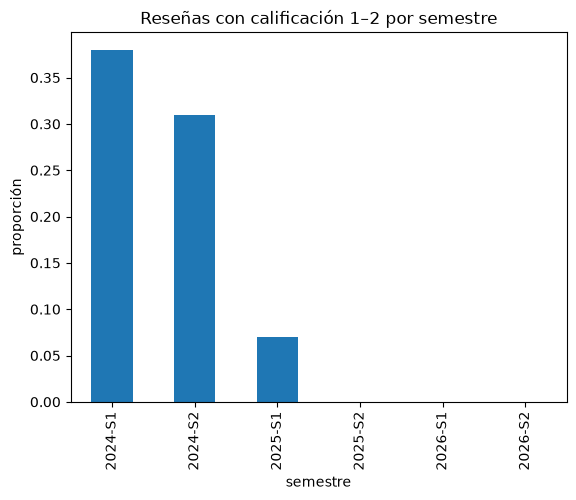

In [8]:
ax = dist["pct_neg"].plot(kind="bar", title="Reseñas con calificación 1–2 por semestre")
ax.set_ylabel("proporción");

**Hallazgo:** las negativas caen de 38 % (2024-S1) a 0 % desde 2025-S2, y el volumen baja de ~35 a ~12 por semestre. Un modelo entrenado con 2024 alertará de más; con datos recientes no se puede medir el recall.

**Método:** partición agrupada y estratificada; muestra reciente revisada a mano; monitoreo de la proporción de alertas (±10 p.p.) en la fase 6.

## 2. Actividad 1 — fila 3: datos personales

In [9]:
print("comentarios:", list(comentarios.columns))
print("clientes:   ", list(clientes.columns))

PERSONALES = {"dni", "nombre", "apellidos", "email"}
print("\nColumnas personales en clientes.csv:", PERSONALES & set(clientes.columns))

comentarios: ['id', 'cliente_id', 'cliente_ciudad', 'cliente_pais', 'calificacion', 'fecha', 'texto']
clientes:    ['id', 'dni', 'nombre', 'apellidos', 'email', 'ciudad', 'pais']

Columnas personales en clientes.csv: {'dni', 'nombre', 'apellidos', 'email'}


**Hallazgo:** `cliente_id` (en reseñas y comentarios) enlaza cada texto con `clientes.csv` (DNI, nombre, email). Ciudad, país y fecha son cuasi-identificadores.

**Método:** minimización (texto, calificación, fecha), seudonimizar `cliente_id` con hash, regex para detectar correos/teléfonos/DNI en el texto, prueba automática (abajo).

In [10]:
import hashlib, re

def seudonimizar(x, sal="mineria-web"):
    return hashlib.sha256(f"{sal}{x}".encode()).hexdigest()[:12]

PATRON_PII = re.compile(r"[\w.+-]+@[\w-]+\.\w+|\b\d{8}\b|\b9\d{8}\b")  # email, DNI, celular PE

for nombre, df in [("resenas", resenas), ("comentarios", comentarios)]:
    n = df["texto"].str.contains(PATRON_PII, na=False).sum()
    print(f"{nombre}: {n} textos con posible dato personal")

def validar_sin_pii(df):
    assert not (PERSONALES & set(df.columns)), "Hay columnas personales"
    assert not df["texto"].str.contains(PATRON_PII, na=False).any(), "Hay PII en el texto"

validar_sin_pii(comentarios[["texto", "calificacion", "fecha"]])
print("OK: conjunto minimizado sin PII")

resenas: 0 textos con posible dato personal
comentarios: 0 textos con posible dato personal
OK: conjunto minimizado sin PII


## 3. Práctica — exploración para el recomendador (paso 1)

In [ ]:
print("Categorías:", productos["categoria"].nunique())
productos["categoria"].value_counts()

In [ ]:
por_cliente = resenas.groupby("cliente_id").size()
sin_resena  = set(productos["id"]) - set(resenas["producto_id"])

resumen = pd.Series({
    "clientes totales": len(clientes),
    "clientes con ≥1 reseña": por_cliente.size,
    "mediana reseñas por cliente": por_cliente.median(),
    "productos totales": len(productos),
    "productos sin reseñas": len(sin_resena),
})
resumen

### Consistencia entre tablas

In [ ]:
n_real = resenas.groupby("producto_id").size()
comp = productos.set_index("id")[["total_resenas"]].join(n_real.rename("en_csv")).fillna(0)
inconsistentes = comp[comp["total_resenas"] != comp["en_csv"]]
print(f"Productos con total_resenas ≠ reseñas en CSV: {len(inconsistentes)} / {len(comp)}")

print("Reseñas con producto inexistente:", (~resenas["producto_id"].isin(productos["id"])).sum())
print("Reseñas con cliente inexistente: ", (~resenas["cliente_id"].isin(clientes["id"])).sum())

## 4. Hallazgos para el informe (punto 3)

| Hallazgo | Implicancia |
|---|---|
| 63 / 120 clientes con reseña; mediana = 1 | Arranque en frío de clientes; perfil = 1 producto; evaluar con *leave-one-out* deja sin historial a la mayoría |
| 36 / 90 productos sin reseñas | Arranque en frío de productos → recomendar por similitud de descripción |
| Reseñas califican la **entrega** | Usarlas como interacción implícita (compra), no como medida de agrado |
| `clientes.csv` con DNI, nombre, email | Excluir del recomendador y del servidor MCP (Ley 29733) |
| 9 categorías × 10 productos | Catálogo balanceado (probablemente sintético) |
| `total_resenas` vs CSV | Completar con el resultado de la celda de consistencia |

---
*Declaración de uso de IA: notebook elaborado con apoyo de Claude (Anthropic); resultados verificados al ejecutarlo.*

In [11]:
import json, urllib.request
from collections import Counter

BASE = "http://localhost:3000/api"
KEY  = "sk_demo_000000000000000000000000000000"   # key demo de docs/API.md (solo lectura en este uso)

def get(ruta):
    req = urllib.request.Request(f"{BASE}{ruta}", headers={"x-api-key": KEY})
    with urllib.request.urlopen(req) as r:
        return json.load(r)

def items(resp):
    """La API puede devolver una lista o un objeto paginado."""
    if isinstance(resp, list):
        return resp
    for k in ("data", "items", "results", "comentarios"):
        if k in resp:
            return resp[k]
    raise ValueError(f"Formato no reconocido: {list(resp)[:10]}")

# 1) Comentarios de tipo 'producto' (la señal de preferencia que no está en los CSV)
resp = get("/comentarios?tipo=producto")
print("Claves de la respuesta:", list(resp) if isinstance(resp, dict) else "lista")
coment_prod = items(resp)
print("Comentarios de producto en la API:", len(coment_prod))
print("Ejemplo:", {k: v for k, v in coment_prod[0].items() if k not in {"texto", "clienteNombre", "clienteApellidos"}} if coment_prod else "—")

# 2) Comparar con total_resenas de productos.csv
campo_prod = next((k for k in ("productoId", "producto_id") if coment_prod and k in coment_prod[0]), None)
if campo_prod:
    n_api = Counter(str(c[campo_prod]) for c in coment_prod)
    comp = productos[["id", "total_resenas"]].copy()
    comp["en_api"] = comp["id"].astype(str).map(n_api).fillna(0).astype(int)
    print(f"\ntotal_resenas coincide con la API en {(comp['total_resenas'] == comp['en_api']).sum()} / {len(comp)} productos")
    print("Productos sin reseña de producto en la API:", (comp["en_api"] == 0).sum())
    display(comp.head(10))

Claves de la respuesta: ['items', 'total']
Comentarios de producto en la API: 318
Ejemplo: {'id': 115, 'tipo': 'producto', 'clienteId': 25, 'productoId': 25, 'ordenId': None, 'calificacion': 4, 'fecha': '2026-08-08'}

total_resenas coincide con la API en 90 / 90 productos
Productos sin reseña de producto en la API: 0


,id,total_resenas,en_api
0,1,4,4
1,2,4,4
2,3,4,4
3,4,4,4
4,5,4,4
5,6,5,5
6,7,4,4
7,8,4,4
8,9,5,5
9,10,4,4


In [12]:
print("total según la API:", resp["total"], "| recibidos:", len(coment_prod))   # ¿faltan páginas?

clientes_con_hist = {c["clienteId"] for c in coment_prod}
por_cli = Counter(c["clienteId"] for c in coment_prod)
print(f"Clientes con ≥1 reseña de producto: {len(clientes_con_hist)} / {len(clientes)}")
print("Mediana de reseñas de producto por cliente:", pd.Series(list(por_cli.values())).median())

total según la API: 318 | recibidos: 318
Clientes con ≥1 reseña de producto: 120 / 120
Mediana de reseñas de producto por cliente: 3.0


In [13]:
  pd.DataFrame(coment_prod).drop(columns=["clienteNombre", "clienteApellidos"], errors="ignore") \
    .to_csv(DATA.parent / "salidas" / "resenas_producto_api.csv", index=False)

In [14]:
salida = DATA.parent / "salidas" / "resenas_producto_api.csv"
pd.DataFrame(coment_prod).drop(columns=["clienteNombre", "clienteApellidos"], errors="ignore") \
  .to_csv(salida, index=False)
print("Guardado en:", salida)

Guardado en: ~/proyectos/mineria-web-2026-2/sesion-de-clase-08/salidas/resenas_producto_api.csv
